In [1]:
import pandas as pd

df = pd.read_csv("../../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["churn"] = (df["Churn"] == "Yes").astype(int)

# Colonnes écartées : l'identifiant, la cible, et les données sensibles
# exclues par choix éthique (cf. docs/architecture.md)
dropped = ["customerID", "gender", "SeniorCitizen", "Partner", "Dependents", "Churn"]
X = df.drop(columns=dropped + ["churn"])
y = df["churn"]

print(X.shape, "| taux de départ :", y.mean().round(3))
X.columns.tolist()

(7043, 15) | taux de départ : 0.265


['tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges']

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(len(X_train), len(X_test), "|", y_train.mean().round(3), y_test.mean().round(3))

5634 1409 | 0.265 0.265


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_cols = [c for c in X.columns if c not in numeric_cols]

preprocess = ColumnTransformer(
    [
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value=0)),
            ("scale", StandardScaler()),
        ]), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ],
    sparse_threshold=0,
)

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, recall_score, roc_auc_score


def evaluate(name, model):
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "modèle": name,
        "AUC": roc_auc_score(y_test, proba),
        "AUC-PR": average_precision_score(y_test, proba),
        "rappel": recall_score(y_test, pred),
        "précision": precision_score(y_test, pred, zero_division=0),
    }


results = [
    evaluate("Référence (toujours « reste »)",
             Pipeline([("prep", preprocess), ("clf", DummyClassifier(strategy="prior"))])),
    evaluate("Régression logistique",
             Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=1000))])),
]
pd.DataFrame(results).round(3)

,modèle,AUC,AUC-PR,rappel,précision
0,Référence (toujours « reste »),0.500,0.265,0.000,0.000
1,Régression logistique,0.841,0.634,0.545,0.638


In [5]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

candidates = {
    "Régression logistique": LogisticRegression(max_iter=1000),
    "Forêt aléatoire": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=200, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, clf in candidates.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["roc_auc", "average_precision"])
    rows.append({
        "modèle": name,
        "AUC (moyenne)": scores["test_roc_auc"].mean(),
        "AUC (écart)": scores["test_roc_auc"].std(),
        "AUC-PR (moyenne)": scores["test_average_precision"].mean(),
        "AUC-PR (écart)": scores["test_average_precision"].std(),
    })

pd.DataFrame(rows).round(3)

,modèle,AUC (moyenne),AUC (écart),AUC-PR (moyenne),AUC-PR (écart)
0,Régression logistique,0.846,0.013,0.660,0.018
1,Forêt aléatoire,0.844,0.010,0.660,0.021
2,Gradient boosting,0.847,0.011,0.668,0.021


In [6]:
from sklearn.model_selection import cross_val_predict

final_model = Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=1000))])

proba_oof = cross_val_predict(
    final_model, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]
print(len(proba_oof), "prédictions obtenues, chacune par un modèle qui n'avait pas vu ce client")

5634 prédictions obtenues, chacune par un modèle qui n'avait pas vu ce client


,seuil,contactés (%),rappel,précision,gain pour 1000 clients (€)
0,0.05,72.93,0.97,0.35,12714.77
1,0.10,62.42,0.94,0.40,14340.61
2,0.15,55.63,0.91,0.44,15166.84
3,0.20,47.87,0.86,0.48,15380.72
4,0.25,42.49,0.81,0.51,15234.29
5,0.30,37.75,0.77,0.54,14992.01
6,0.35,33.35,0.72,0.57,14537.63
7,0.40,29.71,0.66,0.59,13722.04
8,0.45,25.54,0.60,0.63,12847.89
9,0.50,22.49,0.56,0.66,12077.56


Seuil le plus rentable : 0.2


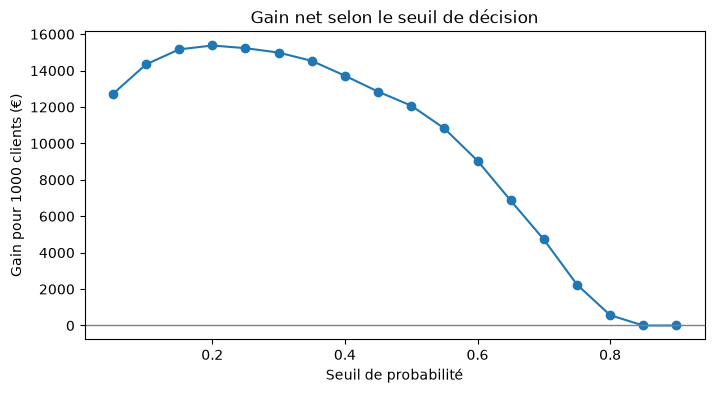

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Hypothèses métier FICTIVES, pour illustrer la méthode (à adapter à un vrai cas)
COUT_OFFRE = 25       # coût d'une action de rétention par client contacté (en euros)
VALEUR_CLIENT = 400   # valeur d'un client conservé (en euros)
TAUX_SUCCES = 0.30    # part des clients contactés qui acceptent de rester

n_departs = int((y_train == 1).sum())
rows = []
for seuil in np.arange(0.05, 0.95, 0.05):
    contactes = proba_oof >= seuil
    detectes = int((contactes & (y_train == 1)).sum())
    nb_contactes = int(contactes.sum())
    gain = detectes * TAUX_SUCCES * VALEUR_CLIENT - nb_contactes * COUT_OFFRE
    rows.append({
        "seuil": round(float(seuil), 2),
        "contactés (%)": 100 * nb_contactes / len(y_train),
        "rappel": detectes / n_departs,
        "précision": detectes / nb_contactes if nb_contactes else 0,
        "gain pour 1000 clients (€)": 1000 * gain / len(y_train),
    })

seuils = pd.DataFrame(rows)
meilleur = seuils.loc[seuils["gain pour 1000 clients (€)"].idxmax()]

display(seuils.round(2))
print("Seuil le plus rentable :", meilleur["seuil"])

plt.figure(figsize=(8, 4))
plt.plot(seuils["seuil"], seuils["gain pour 1000 clients (€)"], marker="o")
plt.axhline(0, color="grey", linewidth=1)
plt.title("Gain net selon le seuil de décision")
plt.xlabel("Seuil de probabilité")
plt.ylabel("Gain pour 1000 clients (€)")
plt.show()

In [8]:
from sklearn.metrics import confusion_matrix

SEUIL = 0.2

final_model.fit(X_train, y_train)
proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= SEUIL).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
n_test = len(y_test)

def gain_pour_1000(vrais_positifs, contactes):
    return 1000 * (vrais_positifs * TAUX_SUCCES * VALEUR_CLIENT - contactes * COUT_OFFRE) / n_test

final_metrics = {
    "seuil": SEUIL,
    "auc": round(float(roc_auc_score(y_test, proba_test)), 3),
    "auc_pr": round(float(average_precision_score(y_test, proba_test)), 3),
    "rappel": round(float(recall_score(y_test, pred_test)), 3),
    "precision": round(float(precision_score(y_test, pred_test)), 3),
    "clients_contactes_pct": round(100 * (tp + fp) / n_test, 1),
    "gain_modele_pour_1000": round(gain_pour_1000(tp, tp + fp)),
    "gain_contacter_tout_le_monde_pour_1000": round(gain_pour_1000(int(y_test.sum()), n_test)),
    "gain_ne_rien_faire_pour_1000": 0,
}
print(pd.Series(final_metrics))
print()
print(pd.DataFrame([[tn, fp], [fn, tp]],
                   index=["reste (réel)", "part (réel)"],
                   columns=["prédit : reste", "prédit : part"]))

seuil                                         0.200
auc                                           0.841
auc_pr                                        0.634
rappel                                        0.850
precision                                     0.468
clients_contactes_pct                        48.300
gain_modele_pour_1000                     15018.000
gain_contacter_tout_le_monde_pour_1000     6852.000
gain_ne_rien_faire_pour_1000                  0.000
dtype: float64

              prédit : reste  prédit : part
reste (réel)             673            362
part (réel)               56            318


In [9]:
import json
from pathlib import Path

import joblib

models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

joblib.dump(final_model, models_dir / "churn_model.joblib")

with open(models_dir / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(final_metrics, f, indent=2, ensure_ascii=False)

print("Modèle et métriques enregistrés dans ml-service/models")

Modèle et métriques enregistrés dans ml-service/models
